<a href="https://colab.research.google.com/github/RanjaniRajendran28/Assignment-2-Data-Visualization-Sivaranjani-16-11-2026/blob/main/Assignment_on_Data_Visualization_16_11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problem Statement
Taxi services generate large amounts of trip data daily, which can be used to understand patterns and
improve operations. However, raw data often contains missing values and is difficult to interpret
without proper analysis.
In this project, you will act as a data analyst to clean, analyze, and visualize taxi data. You will handle
missing values, explore trends, and create visualizations to gain insights into fare, distance, and
customer behavior using Pandas, Matplotlib, and Seaborn.
Assignment Tasks:
1) Loading the Taxis Dataset using the following code:

import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

2) Handling Missing Values
● Check for missing values in the dataset and identify columns with missing data.
● Impute missing values using appropriate strategies based on the column type (e.g.,
using the mean, median, or mode for numerical columns and the mode for categorical
columns).
● For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.

In [1]:
#1. Loading the Taxis Dataset
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

Explanation :
pandas is used for data manipulation and cleaning.

seaborn is used to load the built-in taxis dataset.

matplotlib is used for data visualization.

df.head() displays the first five records.

In [2]:
#2. Handling Missing Values
#Step 1: Check for missing values
# Check missing values in each column
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [3]:
#To display only columns containing missing values:


missing_values = df.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [4]:
#To calculate the percentage of missing values:

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Values Percentage:")
print(missing_percentage[missing_percentage > 0])

Missing Values Percentage:
payment            0.683973
pickup_zone        0.404166
dropoff_zone       0.699518
pickup_borough     0.404166
dropoff_borough    0.699518
dtype: float64


In [10]:
#Step 2: Handle missing numerical values
#Numerical columns can be filled using the median or mean.
#Mean: Suitable when data has no significant outliers.
#Median: Suitable when data contains outliers or is skewed.


# Identify numerical columns
numerical_columns = df.select_dtypes(include=['number']).columns

# Fill missing numerical values with median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

In [14]:
#3: Handle missing categorical values
#Categorical columns can be filled using the mode (most frequently occurring value).
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns


# Fill missing categorical values with mode

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [15]:
#Step 4: Remove rows with critical missing values

# Remove rows with missing pickup or drop-off timestamps
df.dropna(subset=['pickup', 'dropoff'], inplace=True)

In [16]:
#Step 5: Verify missing values after cleaning

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check total missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Display cleaned dataset
print(df.head())

Missing values after cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Total Missing Values: 0
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash 

Taxi Data Analysis Project – Data Visualization using Matplotlib and Pandas
In this section, we will create five different visualizations using Matplotlib, Pandas, and Seaborn to understand taxi trip patterns, fare distribution, payment methods, distance, and tips.

1. Import Libraries and Prepare Dataset

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Remove rows with missing values in important columns
df = df.dropna(subset=[
    'pickup', 'fare', 'pickup_borough',
    'payment', 'distance', 'tip'
])

# Set visualization style
sns.set_style("whitegrid")

2. Line Chart – Fare Over Time
Objective: Visualize how taxi fares change over time using pickup timestamps.

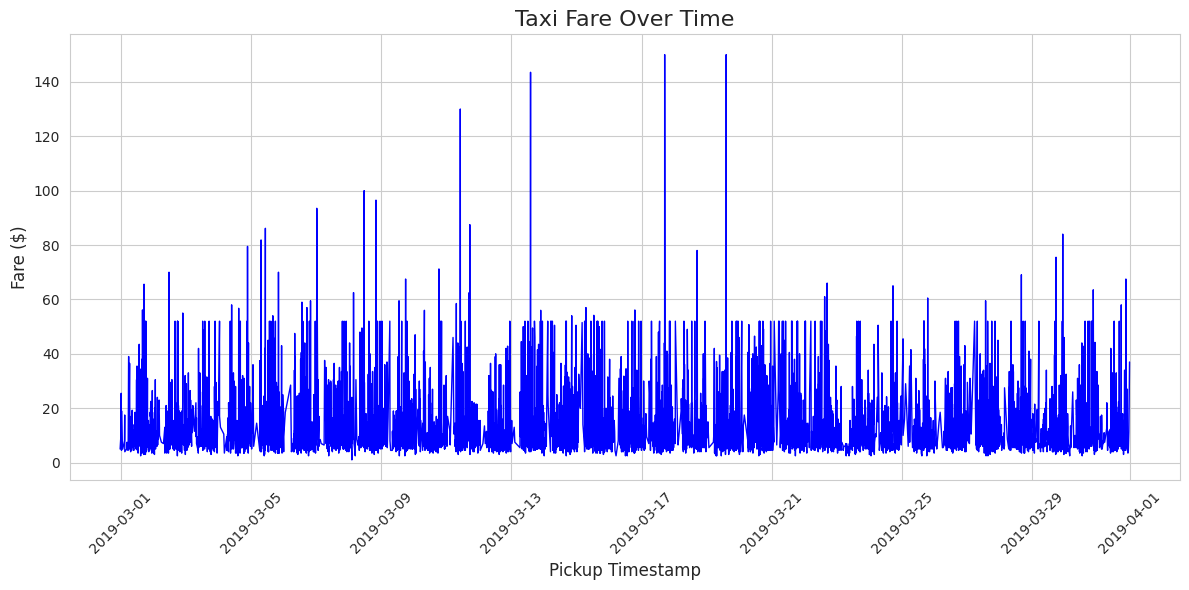

In [18]:
# Sort data by pickup timestamp
df_sorted = df.sort_values(by='pickup')

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    df_sorted['pickup'],
    df_sorted['fare'],
    color='blue',
    linewidth=1
)

plt.title('Taxi Fare Over Time', fontsize=16)
plt.xlabel('Pickup Timestamp', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

3. Bar Chart – Total Fare by Pickup Borough
Objective: Compare the total fare collected from different pickup boroughs

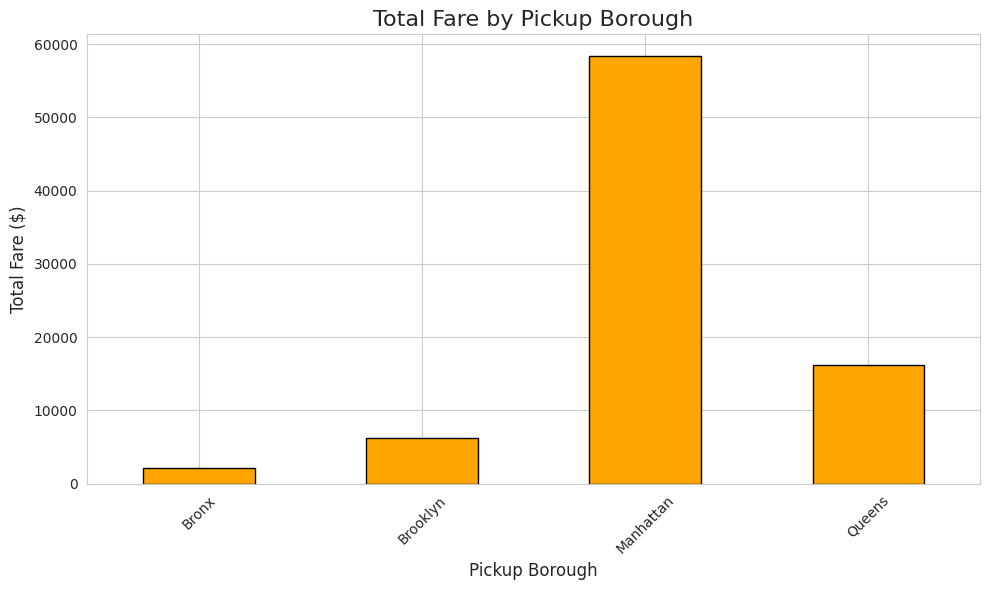

In [19]:
# Group data by pickup borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(10, 6))

borough_fare.plot(
    kind='bar',
    color='orange',
    edgecolor='black'
)

plt.title('Total Fare by Pickup Borough', fontsize=16)
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Total Fare ($)', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4. Pie Chart – Distribution of Trips by Payment Method
Objective: Show the percentage distribution of trips based on payment methods, such as credit card and cash.

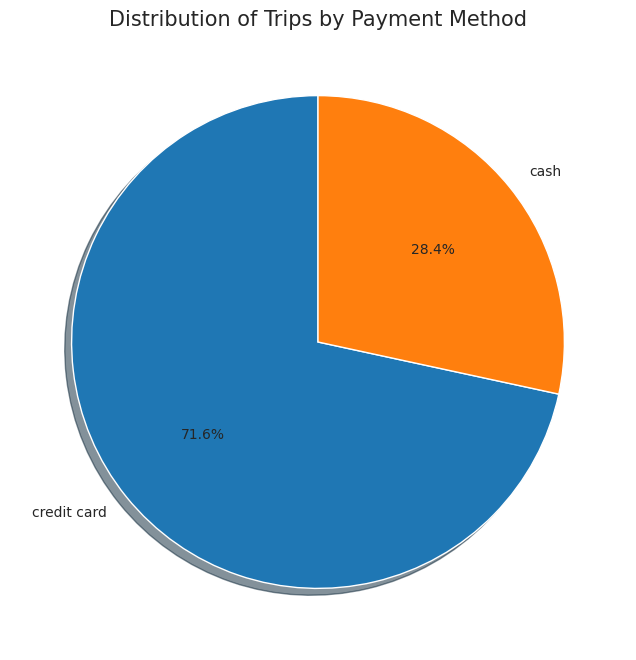

In [20]:
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    shadow=True
)

plt.title('Distribution of Trips by Payment Method', fontsize=15)

plt.show()

5. Histogram – Distribution of Taxi Trip Distance
Objective: Understand how taxi trip distances are distributed.

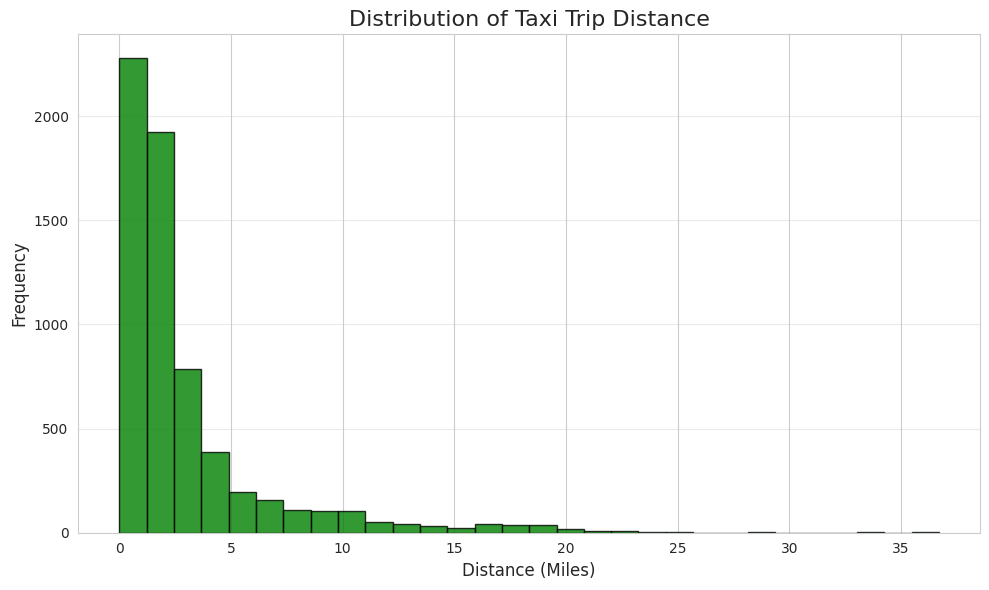

In [21]:
# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df['distance'],
    bins=30,
    color='green',
    edgecolor='black',
    alpha=0.8
)

plt.title('Distribution of Taxi Trip Distance', fontsize=16)
plt.xlabel('Distance (Miles)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

6. Box Plot – Distribution of Tips by Pickup Borough
Objective: Compare the distribution of tip amounts across different pickup boroughs.

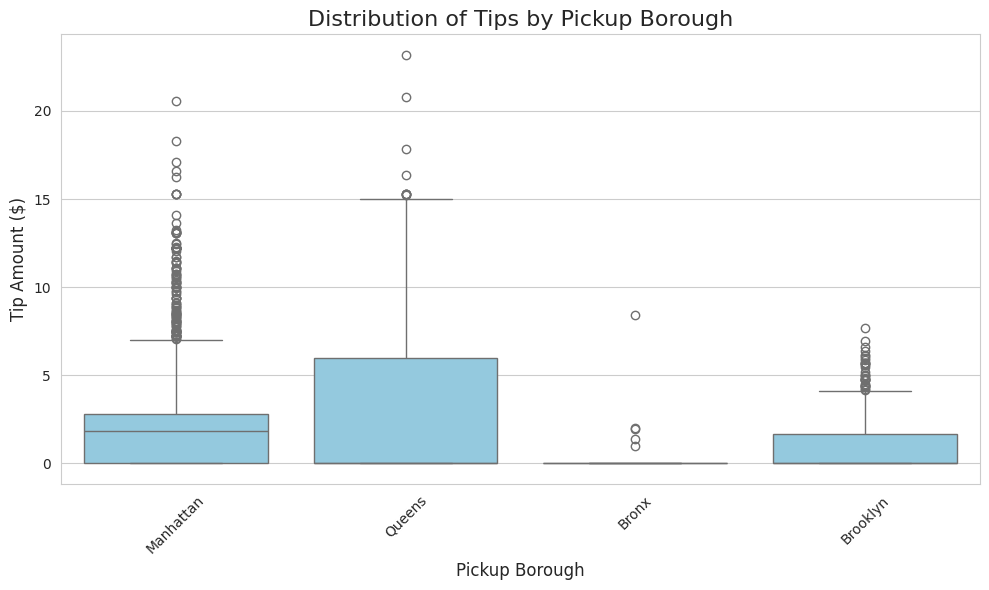

In [22]:
# Create box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip',
    color='skyblue'
)

plt.title('Distribution of Tips by Pickup Borough', fontsize=16)
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Tip Amount ($)', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Log in
Sign up for free
Problem Statement
Taxi services generate large amounts of trip data daily, which can be used to understand patterns and
improve operations. However, raw data often contains missing values and is difficult to interpret
without proper analysis.
In this project, you will act as a data analyst to clean, analyze, and visualize taxi data. You will handle
missing values, explore trends, and create visualizations to gain insights into fare, distance, and
customer behavior using Pandas, Matplotlib, and Seaborn.
Assignment Tasks:
1) Loading the Taxis Dataset using the following code:

import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

2) Handling Missing Values
● Check for missing values in the dataset and identify columns with missing data.
● Impute missing values using appropriate strategies based on the column type (e.g.,
using the mean, median, or mode for numerical columns and the mode for categorical
columns).
● For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.

Taxi Data Analysis Project – Loading Dataset and Handling Missing Values
This assignment uses Python libraries Pandas, Matplotlib, and Seaborn to clean and analyze taxi trip data.

Below is the Python code for completing Task 1 and Task 2, along with explanations and expected outputs.

1. Loading the Taxis Dataset
Python code:


python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
print(df.head())
Explanation:

pandas is used for data manipulation and cleaning.

seaborn is used to load the built-in taxis dataset.

matplotlib is used for data visualization.

df.head() displays the first five records.

To check the dataset structure:


python
# Dataset information
print(df.info())

# Number of rows and columns
print("Dataset Shape:", df.shape)

# Statistical summary
print(df.describe())
2. Handling Missing Values
Step 1: Check for missing values

python
# Check missing values in each column
print(df.isnull().sum())
To display only columns containing missing values:


python
missing_values = df.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])
To calculate the percentage of missing values:


python
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Values Percentage:")
print(missing_percentage[missing_percentage > 0])
Step 2: Handle missing numerical values
Numerical columns can be filled using the median or mean.

Mean: Suitable when data has no significant outliers.

Median: Suitable when data contains outliers or is skewed.


python
# Identify numerical columns
numerical_columns = df.select_dtypes(include=['number']).columns

# Fill missing numerical values with median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())
Step 3: Handle missing categorical values
Categorical columns can be filled using the mode (most frequently occurring value).


python
# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

# Fill missing categorical values with mode
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
Step 4: Remove rows with critical missing values
Some columns contain important information that should not be guessed.

For example, pickup and drop-off timestamps are important for trip analysis. Rows with missing timestamps can be removed.


python
# Remove rows with missing pickup or drop-off timestamps
df.dropna(subset=['pickup', 'dropoff'], inplace=True)
Step 5: Verify missing values after cleaning

python
# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check total missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Display cleaned dataset
print(df.head())
3. Complete Python Code
You can copy and execute the following code in Google Colab, Jupyter Notebook, or VS Code.


python

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the taxis dataset
df = sns.load_dataset("taxis")

print("Original Dataset:")
print(df.head())

# 2. Dataset information
print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

# 3. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("\nMissing Value Percentage:")
print(missing_percentage[missing_percentage > 0])

# 5. Handle numerical missing values
numerical_columns = df.select_dtypes(include=['number']).columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# 6. Handle categorical missing values
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# 7. Remove rows with missing critical timestamps
df.dropna(subset=['pickup', 'dropoff'], inplace=True)

# 8. Verify cleaned dataset
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nCleaned Dataset:")
print(df.head())

print("\nFinal Dataset Shape:")
print(df.shape)
4. Conclusion
The taxis dataset was successfully loaded using Seaborn. Missing values were identified and handled using appropriate data-cleaning techniques.

The following operations were performed:

Loaded the taxis dataset.

Checked missing values in all columns.

Calculated the percentage of missing values.

Replaced missing numerical values using the median.

Replaced missing categorical values using the mode.

Removed records with missing critical timestamps.

Verified the dataset after cleaning.

Result: The dataset is now cleaner and ready for further exploratory data analysis and visualization.

Next step: Assignment Task 3 can focus on analyzing taxi fare, trip distance, payment methods, passenger counts, and pickup/drop-off trends using Pandas, Matplotlib, and Seaborn.


Log in to analyze data, create charts, and build tables for free.


Log in

Sign up for free
Visualizations using Matplotlib/Pandas Plot:
★ Line Chart
Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and
fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

★ Bar Chart
Create a bar chart to show the total fare for each pickup_borough. Group the data by
pickup_borough and sum the fare for each group.
★ Pie Chart
Plot a pie chart showing the distribution of trips based on the payment method (credit card,
cash, etc.). Each slice should represent the count of trips for a specific payment method.
★ Histogram
Create a histogram to visualize the distribution of distance. Customize the number of bins for
better granularity and ensure the plot is easy to interpret.
★ Box Plot
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use
pickup_borough as the categorical axis and tip as the numeric axis.

Taxi Data Analysis Project – Data Visualization using Matplotlib and Pandas
In this section, we will create five different visualizations using Matplotlib, Pandas, and Seaborn to understand taxi trip patterns, fare distribution, payment methods, distance, and tips.

1. Import Libraries and Prepare Dataset

python
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Remove rows with missing values in important columns
df = df.dropna(subset=[
    'pickup', 'fare', 'pickup_borough',
    'payment', 'distance', 'tip'
])

# Set visualization style
sns.set_style("whitegrid")
2. Line Chart – Fare Over Time
Objective: Visualize how taxi fares change over time using pickup timestamps.


python
# Sort data by pickup timestamp
df_sorted = df.sort_values(by='pickup')

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    df_sorted['pickup'],
    df_sorted['fare'],
    color='blue',
    linewidth=1
)

plt.title('Taxi Fare Over Time', fontsize=16)
plt.xlabel('Pickup Timestamp', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()
Explanation:

X-axis represents the pickup timestamp.

Y-axis represents the taxi fare.

The line chart helps identify changes and fluctuations in fares over time.

Python Charts - Line Chart with Confidence Interval in Python

3. Bar Chart – Total Fare by Pickup Borough
Objective: Compare the total fare collected from different pickup boroughs.


python
# Group data by pickup borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(10, 6))

borough_fare.plot(
    kind='bar',
    color='orange',
    edgecolor='black'
)

plt.title('Total Fare by Pickup Borough', fontsize=16)
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Total Fare ($)', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
Explanation:

Groups taxi trips according to pickup borough.

Calculates the total fare for each borough.

The bar chart makes it easy to compare fare revenue across boroughs.

Day 32 — Data Visualization Day 3: Line & Bar Charts in Matplotlib | by Ratnesh | Medium

4. Pie Chart – Distribution of Trips by Payment Method
Objective: Show the percentage distribution of trips based on payment methods, such as credit card and cash.


python
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    shadow=True
)

plt.title('Distribution of Trips by Payment Method', fontsize=15)

plt.show()
Explanation:

value_counts() calculates the number of trips for each payment method.

autopct displays the percentage of each slice.

Each slice represents a payment method.

Tutorial (Tableau): Creating Donut Charts | by Michele Bedin | Medium

5. Histogram – Distribution of Taxi Trip Distance
Objective: Understand how taxi trip distances are distributed.


python
# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df['distance'],
    bins=30,
    color='green',
    edgecolor='black',
    alpha=0.8
)

plt.title('Distribution of Taxi Trip Distance', fontsize=16)
plt.xlabel('Distance (Miles)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()
Explanation:

The histogram displays the frequency of different trip distances.

bins=30 divides the distance values into 30 intervals.

The X-axis represents distance in miles.

The Y-axis represents the number of trips.

Taxi Price Regression 🚕 | Kaggle

6. Box Plot – Distribution of Tips by Pickup Borough
Objective: Compare the distribution of tip amounts across different pickup boroughs.


python
# Create box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip',
    color='skyblue'
)

plt.title('Distribution of Tips by Pickup Borough', fontsize=16)
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Tip Amount ($)', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
Explanation:

X-axis represents pickup boroughs.

Y-axis represents tip amounts.

The box represents the interquartile range (IQR).

The line inside the box represents the median.

Individual points outside the whiskers indicate potential outliers.

statannotations: Add Statistical Significance Annotations on Seaborn Plots | by Khuyen Tran | TDS Archive | Medium

7. Complete Python Code
The following code combines all five visualizations into one program.


python

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = sns.load_dataset("taxis")

# Convert pickup column to datetime
df['pickup'] = pd.to_datetime(df['pickup'])

# Set visualization style
sns.set_style("whitegrid")

# 1. Line Chart - Fare Over Time
df_sorted = df.dropna(subset=['pickup', 'fare']).sort_values('pickup')

plt.figure(figsize=(12, 6))
plt.plot(df_sorted['pickup'], df_sorted['fare'],
         color='blue', linewidth=1)

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Bar Chart - Total Fare by Pickup Borough
borough_fare = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(10, 6))
borough_fare.plot(kind='bar', color='orange',
                  edgecolor='black')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Pie Chart - Payment Method Distribution
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(payment_counts,
        labels=payment_counts.index,
        autopct='%1.1f%%',
        startangle=90)

plt.title('Distribution of Trips by Payment Method')
plt.show()

# 4. Histogram - Distance Distribution
plt.figure(figsize=(10, 6))
plt.hist(df['distance'].dropna(),
         bins=30,
         color='green',
         edgecolor='black')

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance (Miles)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Box Plot - Tips by Pickup Borough
plt.figure(figsize=(10, 6))

sns.boxplot(data=df.dropna(subset=['pickup_borough', 'tip']),
            x='pickup_borough',
            y='tip',
            color='skyblue')

plt.title('Distribution of Tips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
8. Conclusion
The five visualizations help us understand different aspects of taxi trip data.

Visualization

Purpose

Line Chart

Analyzes fare changes over time

Bar Chart

Compares total fare by pickup borough

Pie Chart

Shows payment method distribution

Histogram

Displays trip distance distribution

Box Plot

Compares tip amounts across boroughs

Final Result: By using Matplotlib and Seaborn, we can visually explore taxi trip data, identify patterns, compare boroughs, understand customer payment preferences, and analyze fare and tip distributions.

Note: These are the expected types of visualizations. Run the code in Google Colab or Jupyter Notebook to generate the actual charts from your dataset.


Visualizations using Seaborn:
★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should
represent the boroughs, and the y-axis should show the count of trips.
★ Scatter Plot
Plot a scatterplot to show the relationship between distance and fare. Use distance on the
x-axis and fare on the y-axis to visualize any correlation. Color the points based on the
pickup_borough to differentiate the trips by their respective boroughs.
★ Heatmap
Plot a heatmap to visualize the correlation between numerical variables such as distance, fare,
tip, tolls, and total. Use a correlation matrix to highlight the relationships.

★ Pair Plot
Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total.
Color the data points according to the pickup_zone column. to compare how different zones
affect these variables.
★ Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the payment
method as the categorical axis and fare as the numeric axis to visualize its distribution.

Taxi Data Analysis Project – Visualizations Using Seaborn
In this section, we will create five visualizations using the Seaborn library to understand taxi trip patterns and relationships between different variables.

The visualizations include:

Count Plot

Scatter Plot

Heatmap

Pair Plot

Violin Plot

1. Import Libraries and Load Dataset

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load taxis dataset
df = sns.load_dataset("taxis")

# Set visualization style
sns.set_style("whitegrid")

# Display first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

2. Count Plot – Number of Trips in Each Pickup Borough
Objective: Visualize the number of taxi trips originating from each pickup borough.

Python Code:

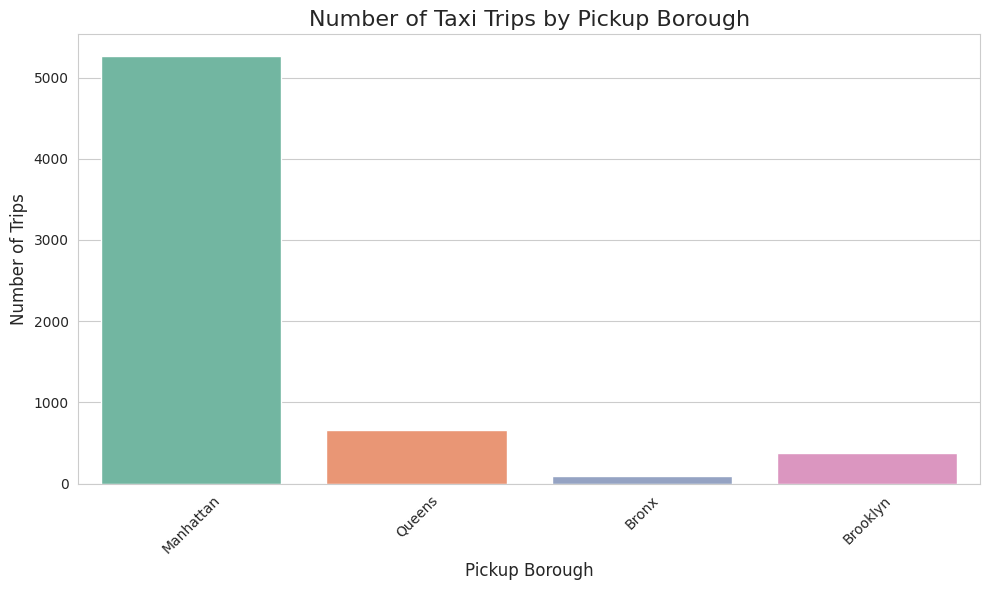

In [24]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='pickup_borough',
    hue='pickup_borough',
    palette='Set2',
    legend=False
)

plt.title('Number of Taxi Trips by Pickup Borough', fontsize=16)
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3. Scatter Plot – Relationship Between Distance and Fare
Objective: Analyze the relationship between taxi trip distance and fare amount.

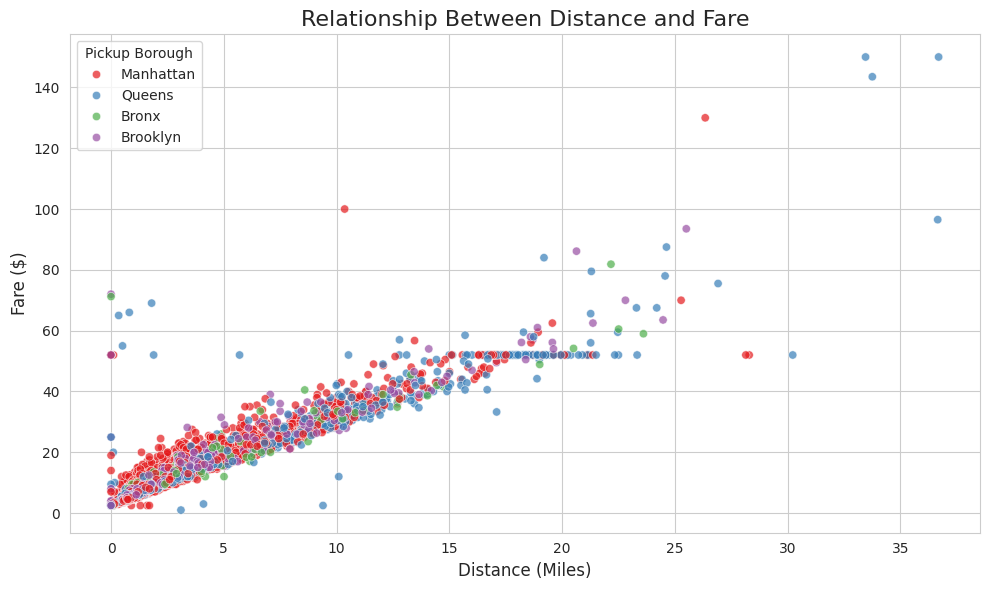

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough',
    palette='Set1',
    alpha=0.7
)

plt.title('Relationship Between Distance and Fare', fontsize=16)
plt.xlabel('Distance (Miles)', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)

plt.legend(title='Pickup Borough')
plt.tight_layout()
plt.show()

4. Heatmap – Correlation Between Numerical Variables
Objective: Visualize the correlation between distance, fare, tip, tolls, and total

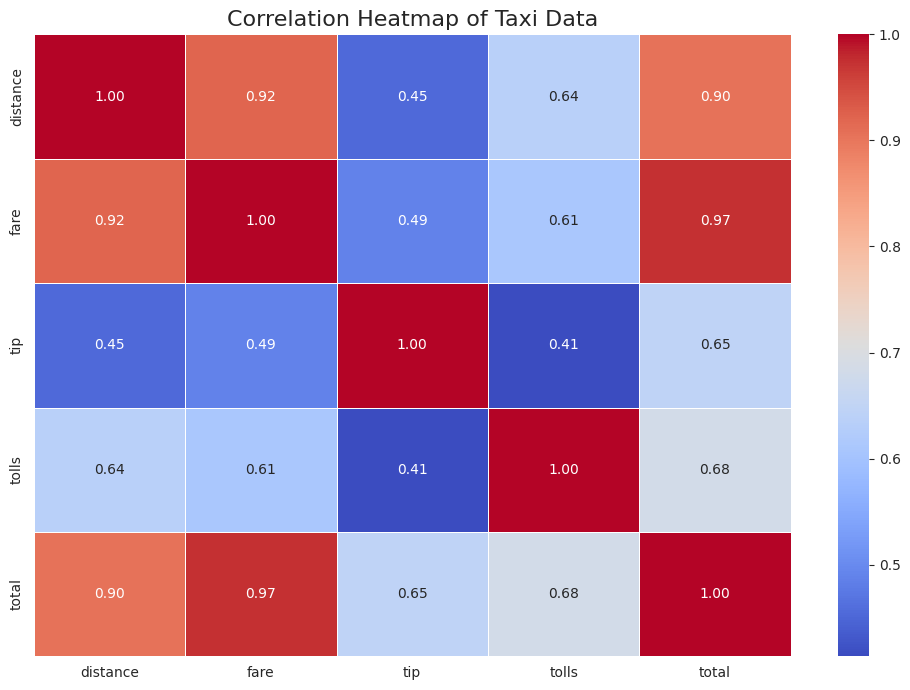

In [26]:
# Select numerical columns
numerical_data = df[
    ['distance', 'fare', 'tip', 'tolls', 'total']
]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Taxi Data', fontsize=16)
plt.tight_layout()
plt.show()

5. Pair Plot – Pairwise Relationships Between Variables
Objective: Visualize pairwise relationships between distance, fare, tip, and total, using pickup zones to distinguish groups.

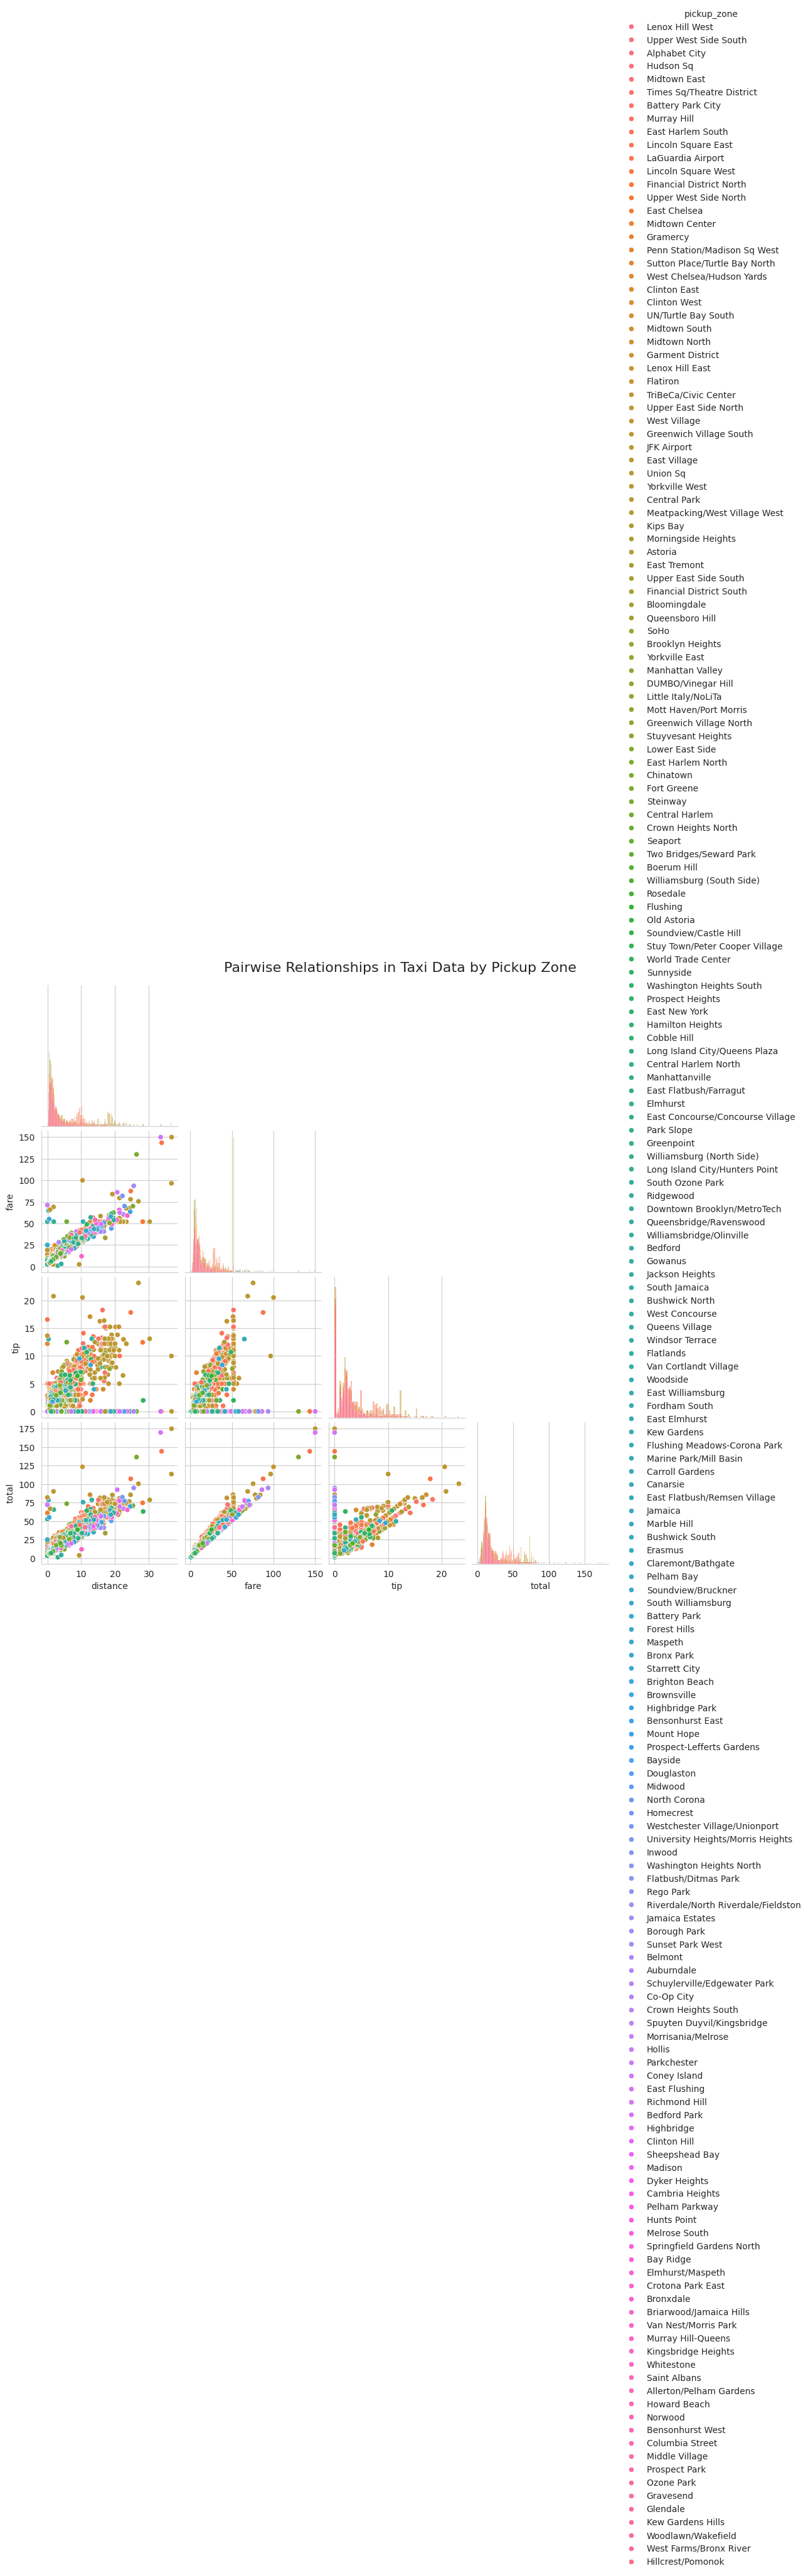

In [28]:
# Remove missing values from selected columns
pair_data = df[
    ['distance', 'fare', 'tip', 'total', 'pickup_zone']
].dropna()

# Create pair plot
sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    palette='husl',
    diag_kind='hist',
    corner=True
)

plt.suptitle(
    'Pairwise Relationships in Taxi Data by Pickup Zone',
    y=1.02,
    fontsize=16
)

plt.show()

6. Violin Plot – Fare Distribution by Payment Method
Objective: Compare fare distributions for different payment methods, such as credit card and cash.

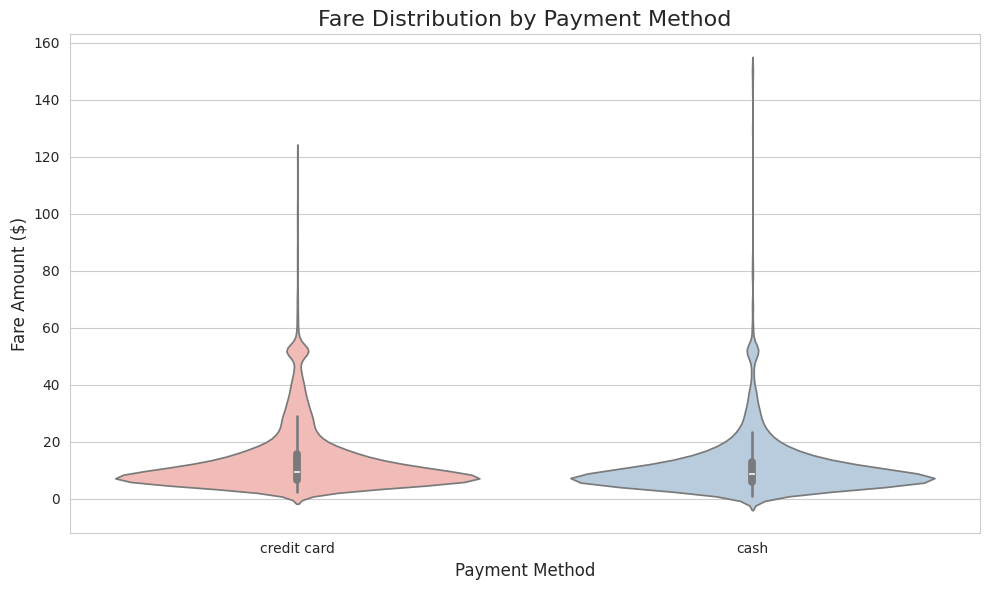

In [29]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df.dropna(subset=['payment', 'fare']),
    x='payment',
    y='fare',
    hue='payment',
    palette='Pastel1',
    legend=False
)

plt.title('Fare Distribution by Payment Method', fontsize=16)
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Fare Amount ($)', fontsize=12)

plt.tight_layout()
plt.show()

8. Conclusion
The five Seaborn visualizations help us understand taxi trip data from different perspectives.

Visualization

Purpose

Count Plot

Identifies the number of trips in each borough

Scatter Plot

Examines the relationship between distance and fare

Heatmap

Identifies correlations between numerical variables

Pair Plot

Compares pairwise relationships between numerical variables across zones

Violin Plot

Compares fare distributions across payment methods